In [1]:
import pandas as pd

In [2]:
import numpy as np

In [3]:
df = pd.read_csv("housing_price_dataset.csv")
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,Rural,1969,215355.283618
1,2459,3,2,Rural,1980,195014.221626
2,1860,2,1,Suburb,1970,306891.012076
3,2294,2,1,Urban,1996,206786.787153
4,2130,5,2,Suburb,2001,272436.239065


In [4]:
df.shape

(50000, 6)

In [5]:
# check datatypes
df.dtypes

SquareFeet        int64
Bedrooms          int64
Bathrooms         int64
Neighborhood     object
YearBuilt         int64
Price           float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   SquareFeet    50000 non-null  int64  
 1   Bedrooms      50000 non-null  int64  
 2   Bathrooms     50000 non-null  int64  
 3   Neighborhood  50000 non-null  object 
 4   YearBuilt     50000 non-null  int64  
 5   Price         50000 non-null  float64
dtypes: float64(1), int64(4), object(1)
memory usage: 2.3+ MB


In [7]:
# display only columns
df.columns

Index(['SquareFeet', 'Bedrooms', 'Bathrooms', 'Neighborhood', 'YearBuilt',
       'Price'],
      dtype='object')

# Data Preprocessing

missing values

In [8]:
df.isnull().sum()

SquareFeet      0
Bedrooms        0
Bathrooms       0
Neighborhood    0
YearBuilt       0
Price           0
dtype: int64

In [9]:
# duplicates
df.duplicated().sum()

np.int64(0)

In [10]:
df["SquareFeet"]

0        2126
1        2459
2        1860
3        2294
4        2130
         ... 
49995    1282
49996    2854
49997    2979
49998    2596
49999    1572
Name: SquareFeet, Length: 50000, dtype: int64

<Axes: ylabel='Density'>

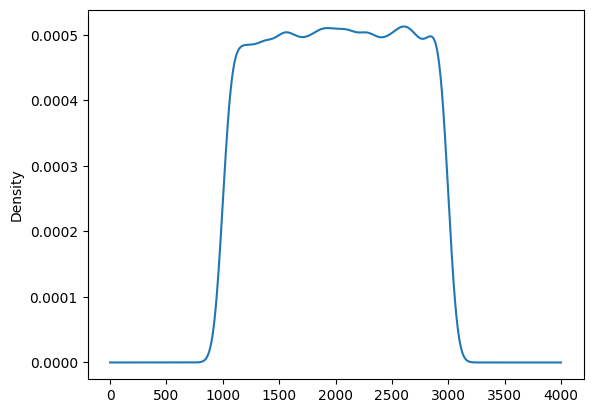

In [11]:
df["SquareFeet"].plot(kind = "kde")

<Axes: ylabel='Frequency'>

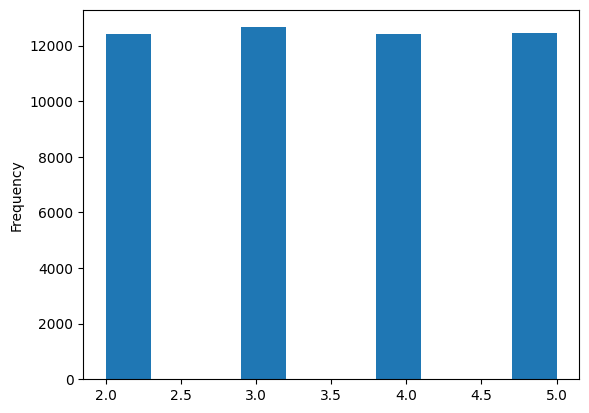

In [12]:
df["Bedrooms"].plot(kind = "hist")

<Axes: ylabel='Frequency'>

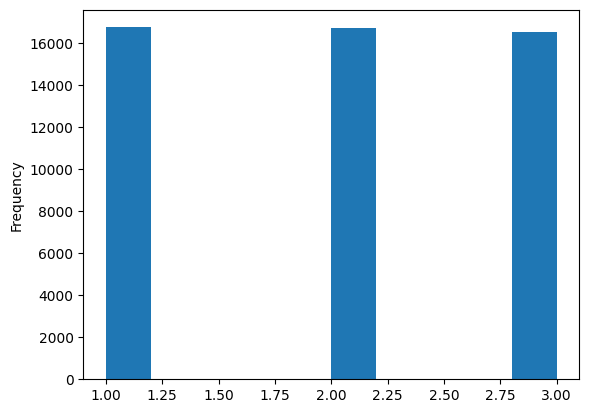

In [13]:
df["Bathrooms"].plot(kind = "hist")

<Axes: xlabel='Neighborhood'>

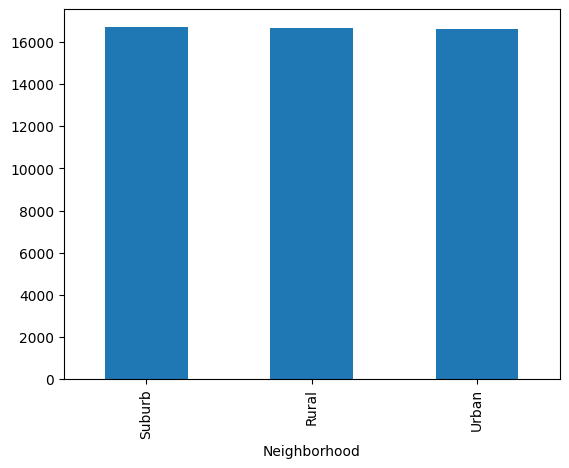

In [14]:
df["Neighborhood"].value_counts().plot(kind = "bar")

<Axes: ylabel='Density'>

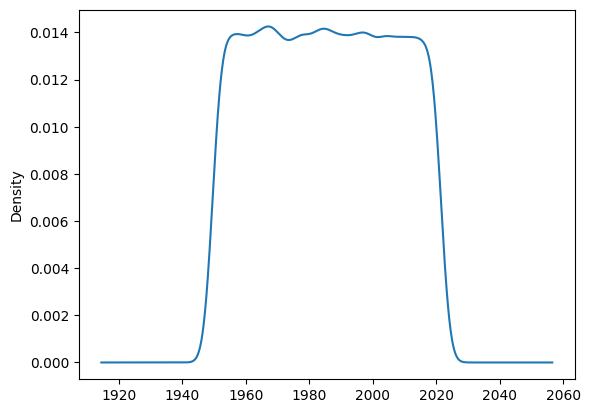

In [15]:
df["YearBuilt"].plot(kind = "kde")

Checking Outliers

<Axes: >

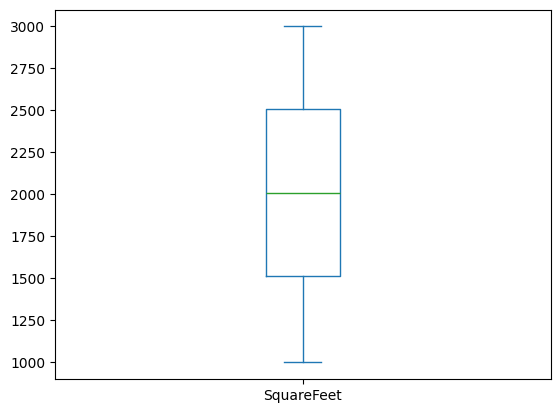

In [16]:
df["SquareFeet"].plot(kind = "box")

<Axes: >

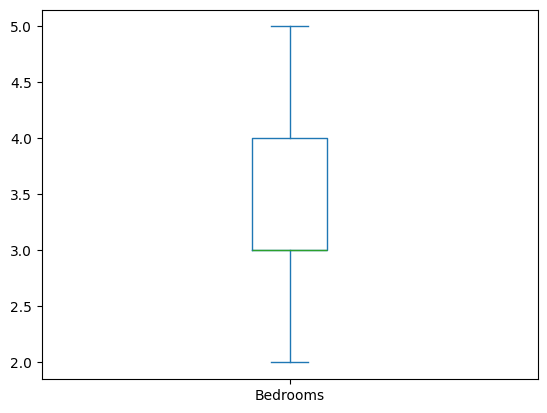

In [17]:
df["Bedrooms"].plot(kind = "box")

<Axes: >

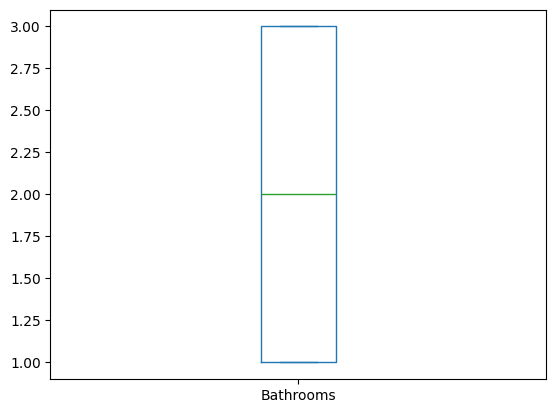

In [18]:
df["Bathrooms"].plot(kind = "box")

<Axes: >

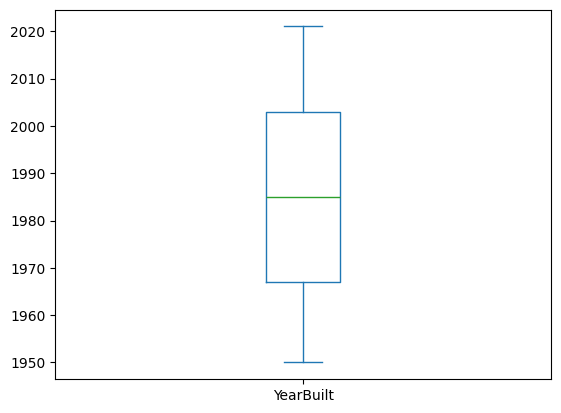

In [19]:
df["YearBuilt"].plot(kind = "box")

In [20]:
df["Price"]

0        215355.283618
1        195014.221626
2        306891.012076
3        206786.787153
4        272436.239065
             ...      
49995    100080.865895
49996    374507.656727
49997    384110.555590
49998    380512.685957
49999    221618.583218
Name: Price, Length: 50000, dtype: float64

In [21]:
# min
df["Price"].min()

np.float64(-36588.16539749279)

In [22]:
df["Price"].max()

np.float64(492195.2599720151)

In [23]:
# convert neg to pos
df["Price"] = np.abs(df["Price"])

In [24]:
df["Price"].min()

np.float64(154.77912007166017)

In [25]:
df["Price"].max()

np.float64(492195.2599720151)

In [26]:
df["Neighborhood"]

0         Rural
1         Rural
2        Suburb
3         Urban
4        Suburb
          ...  
49995     Rural
49996    Suburb
49997    Suburb
49998     Rural
49999     Rural
Name: Neighborhood, Length: 50000, dtype: object

In [27]:
df["Neighborhood"].unique()

array(['Rural', 'Suburb', 'Urban'], dtype=object)

In [28]:
# encode manually
df["Neighborhood"] = df["Neighborhood"].map({"Rural":0, "Suburb":1, "Urban":2})

In [29]:
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,0,1969,215355.283618
1,2459,3,2,0,1980,195014.221626
2,1860,2,1,1,1970,306891.012076
3,2294,2,1,2,1996,206786.787153
4,2130,5,2,1,2001,272436.239065


In [30]:
df.dtypes

SquareFeet        int64
Bedrooms          int64
Bathrooms         int64
Neighborhood      int64
YearBuilt         int64
Price           float64
dtype: object

# Model Building

In [31]:
df.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt,Price
0,2126,4,1,0,1969,215355.283618
1,2459,3,2,0,1980,195014.221626
2,1860,2,1,1,1970,306891.012076
3,2294,2,1,2,1996,206786.787153
4,2130,5,2,1,2001,272436.239065


In [32]:
X = df.drop(columns = ["Price"]) # X contains inputs/features
X.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
0,2126,4,1,0,1969
1,2459,3,2,0,1980
2,1860,2,1,1,1970
3,2294,2,1,2,1996
4,2130,5,2,1,2001


In [33]:
y = df["Price"]
y.head()

0    215355.283618
1    195014.221626
2    306891.012076
3    206786.787153
4    272436.239065
Name: Price, dtype: float64

In [34]:
import sklearn

In [35]:
from sklearn.model_selection import train_test_split

In [36]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size = 0.2,
    random_state = 29
)

In [37]:
X_train.head()

,SquareFeet,Bedrooms,Bathrooms,Neighborhood,YearBuilt
20754,2598,2,1,0,1964
25150,1626,5,3,1,2006
35278,2445,4,1,2,1968
45456,1658,3,2,0,1976
36913,1640,5,3,2,1966


In [38]:
print("The training input shape:", X_train.shape)
print("The training output shape:", y_train.shape) 

print("The testing input shape:", X_test.shape)
print("The testing output shape:", y_test.shape)

The training input shape: (40000, 5)
The training output shape: (40000,)
The testing input shape: (10000, 5)
The testing output shape: (10000,)


In [49]:
from sklearn.metrics import root_mean_squared_error

In [39]:
# linear regression

from sklearn.linear_model import LinearRegression

In [40]:
# create model
lr = LinearRegression()
lr

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [41]:
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [53]:
y_pred = lr.predict(X_test)
print(y_pred)

[190145.57802282 229343.15083813 153026.23321934 ... 236876.07203573
 302191.15291291 257917.69008535]


In [52]:
## KNN Regressor

from sklearn.neighbors import KNeighborsRegressor
knn = KNeighborsRegressor()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(y_pred)

root_mean_squared_error(y_test, y_pred)

[242394.02692398 233124.35542548 166785.71286541 ... 247062.19657432
 284017.78608389 234336.72830738]


55146.35201876714

In [51]:
## Decision Tree Regressor

from sklearn.tree import DecisionTreeRegressor
knn = DecisionTreeRegressor()
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)
print(y_pred)

root_mean_squared_error(y_test, y_pred)

[215299.47100392 187359.58164529 192982.39919138 ... 284505.59786719
 297871.71407468 267888.97511618]


72764.40390906444

# Model Deployment

In [54]:
import warnings
warnings.filterwarnings('ignore')

In [55]:
sqft = 1700
bed = 2
bath = 1
neighbor = 1
year = 2014
lr.predict([[sqft, bed, bath, neighbor, year]])[0]

np.float64(183277.04843446473)

In [56]:
# pickle --> Python Library used to save python objects into files

In [57]:
import pickle

In [59]:
with open(r"model.pkl", 'wb') as file:
    pickle.dump(lr, file)

# pickle.dump() = trained model is saved into model.pkl

In [63]:
with open(r"model.pkl", "rb") as file:
    model = pickle.load(file)

model

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [65]:
def Prediction(sqft, bed, bath, neighbor, year):
    return model.predict([[sqft, bed, bath, neighbor, year]])[0]


In [67]:
pip install gradio

INFO: pip is looking at multiple versions of fastapi to determine which version is compatible with other requirements. This could take a while.
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/31.4 MB ? eta -:--:--
   -------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
datasets 4.8.4 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
langchain-hugging

In [68]:
import gradio as gr

In [69]:
iface = gr.Interface(fn = Prediction, 
                    title = "House Price Prediction",
                    outputs = gr.Textbox(label = "Predicted Price"),
                    inputs = [
                        gr.Number(label = "SQFT"),
                        gr.Number(label = "No.of Bed Rooms"),
                        gr.Number(label = "No.of Bath Rooms"),
                        gr.Number(label = "Neighbourhood"),
                        gr.Number(label = "Year"),
                        
                    ]
                    )

In [70]:
## launch the Application

# private
# iface.launch()

# public
iface.launch(share = True)

# share = True --> you will see public url

* Running on local URL:  http://127.0.0.1:7860
* Running on public URL: https://ce970816973ed77c3d.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
